In [7]:
!pip install -q transformers datasets seqeval accelerate bitsandbytes
!pip install -q sentence-transformers hdbscan umap-learn scikit-learn
!pip install -q faiss-gpu langchain langchain-community langchain-huggingface

In [23]:
import pandas as pd
import numpy as np
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForTokenClassification, TrainingArguments, Trainer, DataCollatorForTokenClassification, set_seed
from seqeval.metrics import precision_score, recall_score, f1_score
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
import hdbscan
import umap
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [11]:
set_seed(42)
df = pd.read_csv("annoted_corpus.csv", keep_default_na=False)
df["token"] = df["token"].astype(str)
sents = df.groupby("note_id", sort=False).agg(tokens=("token", list), tags=("tag", list)).reset_index()
tags = sorted(df["tag"].unique(), key=lambda t: (t != "O", t))
label2id = {t: i for i, t in enumerate(tags)}
id2label = {i: t for t, i in label2id.items()}
train_s, tmp = train_test_split(sents, test_size=0.2, random_state=42)
val_s, test_s = train_test_split(tmp, test_size=0.5, random_state=42)
MODEL="sagorsarker/bangla-bert-base"
tok = AutoTokenizer.from_pretrained(MODEL)
def encode(batch):
    enc= tok(batch["tokens"], is_split_into_words=True, truncation=True, max_length=128)
    all_labels = []
    for i, tg in enumerate(batch["tags"]):
        prev, lab = None, []
        for w in enc.word_ids(batch_index=i):
            if w is None:   lab.append(-100)
            elif w != prev: lab.append(label2id[tg[w]])
            else:           lab.append(-100)
            prev= w
        all_labels.append(lab)
    enc["labels"] = all_labels
    return enc
def to_ds(d):
    ds = Dataset.from_dict({"tokens": d.tokens.tolist(), "tags": d.tags.tolist()})
    return ds.map(encode, batched=True, remove_columns=["tokens", "tags"])
train_ds, val_ds, test_ds = to_ds(train_s), to_ds(val_s), to_ds(test_s)
all_train_labels = [label for seq in train_ds["labels"] for label in seq if label != -100]
class_counts = np.bincount(all_train_labels, minlength=len(tags))
class_counts = np.maximum(class_counts, 1)
class_weights = len(all_train_labels) / (len(tags) * class_counts)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to("cuda" if torch.cuda.is_available() else "cpu")
class WeightedNERTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.CrossEntropyLoss(weight=class_weights_tensor)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss
def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    true_l, pred_l = [], []
    for pr, lb in zip(preds, p.label_ids):
        true_l.append([id2label[l] for l in lb if l != -100])
        pred_l.append([id2label[p] for p, l in zip(pr, lb) if l != -100])
    return {"precision": precision_score(true_l, pred_l), "recall": recall_score(true_l, pred_l), "f1": f1_score(true_l, pred_l)}
model= AutoModelForTokenClassification.from_pretrained(MODEL, num_labels=len(tags), id2label=id2label, label2id=label2id)
args = TrainingArguments(
    output_dir="ner-out", learning_rate=3e-5, num_train_epochs=25,
    per_device_train_batch_size=16, per_device_eval_batch_size=32,
    weight_decay=0.01, eval_strategy="epoch", save_strategy="epoch",
    load_best_model_at_end=True, metric_for_best_model="f1", fp16=torch.cuda.is_available(), report_to="none"
)
trainer = WeightedNERTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds, data_collator=DataCollatorForTokenClassification(tok), compute_metrics=compute_metrics)
trainer.train()

Map:   0%|          | 0/609 [00:00<?, ? examples/s]

Map:   0%|          | 0/76 [00:00<?, ? examples/s]

Map:   0%|          | 0/77 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: sagorsarker/bangla-bert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params

Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,No log,2.429056,0.377358,0.744186,0.500782
2,No log,2.003424,0.510145,0.818605,0.628571
3,No log,2.126146,0.554859,0.823256,0.662921
4,No log,2.141263,0.682310,0.879070,0.768293
5,No log,2.381986,0.703704,0.883721,0.783505
6,No log,2.425965,0.763052,0.883721,0.818966
7,No log,2.573221,0.806723,0.893023,0.847682
8,No log,2.650796,0.804255,0.879070,0.840000
9,No log,2.858961,0.836283,0.879070,0.857143
10,No log,2.758598,0.823276,0.888372,0.854586


... (22 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=975, training_loss=0.14294212848712237, metrics={'train_runtime': 1519.9109, 'train_samples_per_second': 10.017, 'train_steps_per_second': 0.641, 'total_flos': 279781563544680.0, 'train_loss': 0.14294212848712237, 'epoch': 25.0})

Generating Embeddings using L3Cube-Pune Bengali Sentence-BERT on CPU to prevent CUDA OOM...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Applying PCA to compress 778 dimensions down to top 5 components...
Running K-Means Clustering for 6 phenotypes...


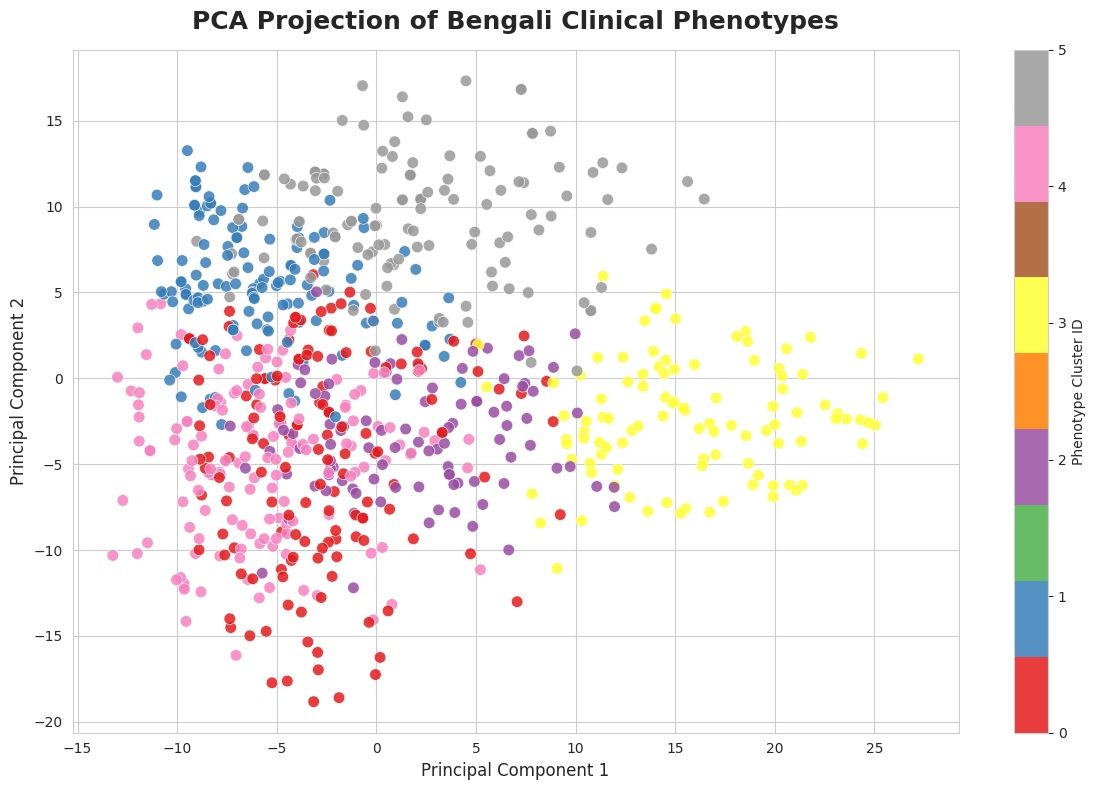


  MANDATORY CLUSTERING METRICS  
Total Unique Phenotypes Discovered: 6
Silhouette Score (Target: Closer to 1.0): 0.2225
Davies-Bouldin Index (Target: Closer to 0.0): 1.3319

Phenotype Cluster 4 (147 clinical notes):
  Dominant Entities: SYMPTOM (216), BODY_SITE (193), TEMPORAL (29)
  Sample Note Snippet: রোগীর ডান দিকের পেটে তীব্র ব্যথা হচ্ছে , অ্যাপেন্ডিসাইটিস সন্দেহ করা হচ্ছে ।...

Phenotype Cluster 0 (143 clinical notes):
  Dominant Entities: SYMPTOM (180), BODY_SITE (165), DIAGNOSIS (11)
  Sample Note Snippet: শ্বাসনালিতে বাইরে থেকে কিছু গেলে কাশির মাধ্য মে তা উঠে আসে ।...

Phenotype Cluster 1 (141 clinical notes):
  Dominant Entities: SYMPTOM (263), BODY_SITE (124), TEMPORAL (37)
  Sample Note Snippet: বয়স বাড়লে একাকিত্ব হবেই ।...

Phenotype Cluster 5 (131 clinical notes):
  Dominant Entities: SYMPTOM (143), BODY_SITE (95), NEGATION_UNCERTAINTY (88)
  Sample Note Snippet: আমার তিন দিন যাবত অনেক মাথা ব্যথা...

Phenotype Cluster 3 (102 clinical notes):
  Dominant Entities: NEGATI

In [27]:
import gc
import torch

#Free GPU memory from the previous NER training
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    gc.collect()

note_texts = [" ".join(tokens) for tokens in sents["tokens"]]
entity_types = ["SYMPTOM", "BODY_SITE", "TEMPORAL", "NEGATION_UNCERTAINTY", "DIAGNOSIS", "TEST", "DOSAGE", "PROCEDURE", "MEDICATION", "TEST_RESULT"]
def extract_entity_frequencies(tags_list):
    freq = {etype: 0 for etype in entity_types}
    for tag in tags_list:
        if tag.startswith("B-"):
            etype = tag.split("-")[1]
            if etype in freq:
                freq[etype] += 1
    return freq
sents['entity_freqs'] = sents['tags'].apply(extract_entity_frequencies)
freq_df = pd.DataFrame(sents['entity_freqs'].tolist())

print("Generating Embeddings using L3Cube-Pune Bengali Sentence-BERT on CPU to prevent CUDA OOM...")
embedder = SentenceTransformer("l3cube-pune/bengali-sentence-bert-nli", device="cpu")
text_embeddings = embedder.encode(note_texts, show_progress_bar=False)

scaler = StandardScaler()
combined_features = np.hstack((text_embeddings, freq_df.values))
combined_scaled = scaler.fit_transform(combined_features)

print("Applying PCA to compress 778 dimensions down to top 5 components...")
pca_dim_reduction= PCA(n_components=5, random_state=42)
reduced_for_clustering= pca_dim_reduction.fit_transform(combined_scaled)

#K-Means Clustering
NUM_CLUSTERS = 6
print(f"Running K-Means Clustering for {NUM_CLUSTERS} phenotypes...")
kmeans = KMeans(n_clusters=NUM_CLUSTERS, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(reduced_for_clustering)
sents["phenotype_cluster"] = cluster_labels

#Visualization
plt.figure(figsize=(12, 8))
sns.set_style("whitegrid")
scatter = plt.scatter(reduced_for_clustering[:, 0], reduced_for_clustering[:, 1],
                      c=cluster_labels, cmap='Set1', s=70, alpha=0.85, edgecolors='w', linewidth=0.5)
plt.title("PCA Projection of Bengali Clinical Phenotypes", fontsize=18, fontweight='bold', pad=15)
plt.xlabel("Principal Component 1", fontsize=12)
plt.ylabel("Principal Component 2", fontsize=12)
plt.colorbar(scatter, label="Phenotype Cluster ID")
plt.tight_layout()
plt.savefig("phenotype_clusters_final.png", dpi=300)
plt.show()

#Evaluation Metrics
sil_score= silhouette_score(reduced_for_clustering, cluster_labels)
db_score= davies_bouldin_score(reduced_for_clustering, cluster_labels)
print(f"\n  MANDATORY CLUSTERING METRICS  ")
print(f"Total Unique Phenotypes Discovered: {NUM_CLUSTERS}")
print(f"Silhouette Score (Target: Closer to 1.0): {sil_score:.4f}")
print(f"Davies-Bouldin Index (Target: Closer to 0.0): {db_score:.4f}")
#Frequency Analysis
top_clusters = pd.Series(cluster_labels).value_counts().head(6)
for cluster_id, count in top_clusters.items():
    print(f"\nPhenotype Cluster {cluster_id} ({count} clinical notes):")
    cluster_notes = sents[sents['phenotype_cluster'] == cluster_id]
    cluster_freqs = pd.DataFrame(cluster_notes['entity_freqs'].tolist()).sum().sort_values(ascending=False)
    dominant_entities = ', '.join([f'{k} ({v})' for k, v in cluster_freqs.head(3).items() if v > 0])
    print(f"  Dominant Entities: {dominant_entities}")
    print(f"  Sample Note Snippet: {' '.join(cluster_notes['tokens'].iloc[0][:15])}...")

In [28]:
from langchain_core.documents import Document
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
docs = [Document(page_content=txt, metadata={"note_id": nid, "cluster": str(cl)})
        for txt, nid, cl in zip(note_texts, sents["note_id"], sents["phenotype_cluster"])]
lc_embedder = HuggingFaceEmbeddings(
    model_name="l3cube-pune/bengali-sentence-bert-nli",
    model_kwargs={'device': 'cpu'}
)
vector_store = FAISS.from_documents(docs, lc_embedder)
retriever = vector_store.as_retriever(search_kwargs={"k": 3})
print(f"FAISS Vector Database successfully built with {len(docs)} clinical notes.")

/tmp/ipykernel_1361/2692573351.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

FAISS Vector Database successfully built with 762 clinical notes.


In [34]:
from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline, BitsAndBytesConfig
from langchain_huggingface import HuggingFacePipeline
from langchain_core.prompts import PromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser
if 'trainer' in locals() or 'trainer' in globals():
    del trainer
if 'model' in locals() or 'model' in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16
)
LLM_NAME = "unsloth/llama-3-8b-Instruct-bnb-4bit"
print(f"Loading {LLM_NAME} in 4-bit mode...")
llm_tokenizer = AutoTokenizer.from_pretrained(LLM_NAME, clean_up_tokenization_spaces=False)
llm_model = AutoModelForCausalLM.from_pretrained(LLM_NAME, quantization_config=bnb_config)

text_pipeline = pipeline(
    "text-generation",
    model=llm_model,
    tokenizer=llm_tokenizer,
    max_new_tokens=150,
    temperature=0.1,
    repetition_penalty=1.1,
    return_full_text=False
)
llm = HuggingFacePipeline(pipeline=text_pipeline)
prompt_template = """<|begin_of_text|><|start_header_id|>system<|end_header_id|>
আপনি একজন নির্ভুল ক্লিনিকাল এআই (AI) অ্যাসিস্ট্যান্ট।
শুধুমাত্র প্রদত্ত ক্লিনিকাল নোটগুলো ব্যবহার করে প্রশ্নের উত্তর দিন।
যদি উত্তরটি নোটের মধ্যে না থাকে, তবে অনুমান করে বা বানিয়ে কিছু বলবেন পণ্ডিতি করবেন না। সেক্ষেত্রে শুধু বলুন: "তথ্যটি নোটে পাওয়া যায়নি"।
আপনার সম্পূর্ণ উত্তরটি অবশ্যই বাংলায় লিখতে হবে।<|eot_id|><|start_header_id|>user<|end_header_id|>
নোটসমূহ (Context):
{context}

প্রশ্ন (Question): {question}<|eot_id|><|start_header_id|>assistant<|end_header_id|>"""

PROMPT = PromptTemplate(template=prompt_template, input_variables=["context", "question"])
def format_docs(docs):
    return "\n\n".join(doc.page_content for doc in docs)
rag_chain = (
    {"context": retriever | format_docs, "question": RunnablePassthrough()}
    | PROMPT
    | llm
    | StrOutputParser()
)
query = "প্যারাসিটামল সাধারণত কী মাত্রায় দেওয়া হয়?"
print(f"\n[QUERY]: {query}")
result = rag_chain.invoke(query)
print(f"\n[GROUNDED ANSWER]:\n{result.strip()}")

Loading unsloth/llama-3-8b-Instruct-bnb-4bit in 4-bit mode...


/usr/local/lib/python3.13/dist-packages/transformers/quantizers/auto.py:279: UserWarning: You passed `quantization_config` or equivalent parameters to `from_pretrained` but the model you're loading already has a `quantization_config` attribute. The `quantization_config` from the model will be used.
  warnings.warn(warning_msg)


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]


[QUERY]: প্যারাসিটামল সাধারণত কী মাত্রায় দেওয়া হয়?


[transformers] Both `max_new_tokens` (=150) and `max_length`(=8192) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



[GROUNDED ANSWER]:
প্যারাসিটামল সাধারণত ৫০০ মিলিগ্রাম দিনে তিনবার খাওয়ার পরামর্শ দেওয়া হয়।
